# Final Model Audit and Refinement

Chronological hyperparameter comparison, unused 2026 data, baseline checks and honest before/after results. The original 2025 evaluation remains historical evidence; it is now exposed development data for this revision.

In [1]:
from pathlib import Path
import sys,json,inspect
import pandas as pd
from IPython.display import display,Image,Markdown
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/refined_selection.json').exists())
if str(root) not in sys.path:sys.path.insert(0,str(root))
from ipo_prediction.refinement_models import RelativePriceRegressor,make_revision_model
from ipo_prediction.refine import chronological_folds,evaluate
from ipo_prediction.data import load_dataset
out=root/'outputs/refinement'
plan=json.loads((root/'config/refinement_plan.json').read_text())
display(pd.Series(plan,name='Refinement protocol').to_frame())

,Refinement protocol
revision,v2
development,All 253 original 2023-2025 IPOs; the previousl...
validation,Eight expanding 2024-2025 quarterly folds; tra...
external_test,Unused 2026 original-cohort IPOs with exact pr...
market_limit,Local Nifty source ends 2026-03-30; later IPOs...
feature_policy,8 compact / 12 context predictors available un...
price_target,Opening price / announced band cap - 1; traini...
regression_selection,"[pooled validation MAE ascending, RMSE ascendi..."
classification_selection,[pooled validation balanced accuracy descendin...
classification_reason,Correct the all-Apply degeneracy by evaluating...


## 1. Correct temporal train / test split

Use eight earlier-data folds for development and the first eligible 2026 S0 for the final training cutoff. Randomly splitting future IPOs into past training would invalidate this decision-time study.

In [2]:
old=load_dataset()
folds=chronological_folds(old)
display(pd.DataFrame([{'fold':f,'cutoff':c,'train':len(t),'validation':len(v)} for f,c,t,v in folds]))
new=pd.read_parquet(root/'data/refinement/external_2026.parquet')
assert set(old.index).isdisjoint(new.ipo_id)
assert old.label_available_at.lt(new.s0_cutoff_at.min()).all()
display(pd.read_csv(root/'data/refinement/external_eligibility.csv').status.value_counts().to_frame('IPOs'))
display(new[['company_name','s0_cutoff_at','market_source_date','market_source_age_days','latest_history_label']])

,fold,cutoff,train,validation
0,2024_Q1,2024-01-09 09:00:00+05:30,59,22
1,2024_Q2,2024-04-03 09:00:00+05:30,80,14
2,2024_Q3,2024-07-03 09:00:00+05:30,94,26
3,2024_Q4,2024-10-08 09:00:00+05:30,121,29
4,2025_Q1,2025-01-06 09:00:00+05:30,149,9
5,2025_Q2,2025-04-28 09:00:00+05:30,159,15
6,2025_Q3,2025-07-02 09:00:00+05:30,171,50
7,2025_Q4,2025-10-03 09:00:00+05:30,217,29


,IPOs
status,
profile unavailable,48
market history ends before IPO opening,28
eligible,17
original NSE band or lot unavailable,1


,company_name,s0_cutoff_at,market_source_date,market_source_age_days,latest_history_label
0,Bharat Coking Coal Limited,2026-01-09 09:00:00+05:30,2026-01-08,1,2025-12-30 23:59:59+05:30
1,Amagi Media Labs Limited,2026-01-13 09:00:00+05:30,2026-01-12,1,2025-12-30 23:59:59+05:30
2,Shadowfax Technologies Limited,2026-01-20 09:00:00+05:30,2026-01-19,1,2026-01-19 23:59:59+05:30
3,Aye Finance Limited,2026-02-09 09:00:00+05:30,2026-02-06,3,2026-01-28 23:59:59+05:30
4,Fractal Analytics Limited,2026-02-09 09:00:00+05:30,2026-02-06,3,2026-01-28 23:59:59+05:30
5,Gaudium IVF and Women Health Limited,2026-02-20 09:00:00+05:30,2026-02-19,1,2026-02-16 23:59:59+05:30
6,Clean Max Enviro Energy Solutions Limited,2026-02-23 09:00:00+05:30,2026-02-20,3,2026-02-16 23:59:59+05:30
7,Shree Ram Twistex Limited,2026-02-23 09:00:00+05:30,2026-02-20,3,2026-02-16 23:59:59+05:30
8,PNGS Reva Diamond Jewellery Limited,2026-02-24 09:00:00+05:30,2026-02-23,1,2026-02-16 23:59:59+05:30
9,Omnitech Engineering Limited,2026-02-25 09:00:00+05:30,2026-02-24,1,2026-02-16 23:59:59+05:30


## 2. Actual estimator and target changes

Relative premium separates price scale from listing performance. Cap-proportional sample weights make absolute-error fitting reflect rupee loss. Missing values and scaling remain fitted inside training folds. The original immutable estimator module is preserved.

In [3]:
print(inspect.getsource(RelativePriceRegressor))
registry=json.loads((out/'candidate_registry.json').read_text())
display(pd.DataFrame(registry))
audit=pd.read_csv(out/'training_audit.csv')
print('Candidates:',len(registry),'candidate/fold fits:',len(audit))
assert audit.external_rows_used.eq(0).all()
assert (pd.to_datetime(audit.latest_training_label)<pd.to_datetime(audit.cutoff)).all()

class RelativePriceRegressor(RegressorMixin, BaseEstimator):
    def __init__(self, estimator=None, baseline='learned'):
        self.estimator = estimator
        self.baseline = baseline
    def fit(self, x, y):
        cap = x.band_high_inr.to_numpy(dtype=float)
        if not np.isfinite(cap).all() or not (cap > 0).all(): raise ValueError('Invalid cap')
        ratio = np.asarray(y, dtype=float) / cap - 1
        if self.baseline == 'cap': self.premium_ = 0.
        elif self.baseline == 'median': self.premium_ = float(np.median(ratio))
        elif self.baseline == 'weighted_median':
            order = np.argsort(ratio)
            self.premium_ = float(ratio[order][np.searchsorted(np.cumsum(cap[order]),cap.sum()/2)])
        else:
            self.estimator_ = clone(self.estimator)
            self.estimator_.fit(x, ratio, model__sample_weight=cap/cap.mean())
        self.n_features_in_ = x.shape[1]
        return self
    def predict(self, x):
        check_is_fitted(self)
    

,id,task,family,feature_set,params
0,regression_cap_compact_1,regression,cap,compact,{}
1,regression_median_compact_1,regression,median,compact,{}
2,regression_weighted_median_compact_1,regression,weighted_median,compact,{}
3,classification_prior_compact_1,classification,prior,compact,{}
4,regression_ridge_compact_1,regression,ridge,compact,{'alpha': 1.0}
5,regression_ridge_compact_2,regression,ridge,compact,{'alpha': 10.0}
6,regression_ridge_compact_3,regression,ridge,compact,{'alpha': 100.0}
7,regression_huber_compact_1,regression,huber,compact,"{'alpha': 0.1, 'epsilon': 1.35}"
8,regression_forest_compact_1,regression,forest,compact,"{'max_depth': 3, 'min_samples_leaf': 5, 'crite..."
9,regression_forest_compact_2,regression,forest,compact,"{'max_depth': None, 'min_samples_leaf': 10, 'c..."


Candidates: 48 candidate/fold fits: 384


## 3. Development tuning and threshold trade-offs

Selected scores use validation labels for selection and are optimistic. Practical guardrails were set on these development results before scoring the new 2026 data; the unconstrained attempt is retained. The new test was not used to set a threshold.

,candidate_id,task,family,threshold,features,converged,mae_inr,rmse_inr,mape_pct,n
0,regression_median_compact_1,regression,median,0.5,8,True,69.300825,121.016619,15.721412,194
1,regression_weighted_median_compact_1,regression,weighted_median,0.5,8,True,70.220610,122.349935,15.860595,194
2,regression_hist_context_2,regression,hist,0.5,12,True,70.468848,119.754154,16.315238,194
3,regression_cap_compact_1,regression,cap,0.5,8,True,74.402990,152.255705,15.053990,194
4,regression_forest_context_2,regression,forest,0.5,12,True,74.666760,125.756340,17.117357,194
5,regression_extra_context_1,regression,extra,0.5,12,True,75.289981,123.631165,17.420109,194
6,regression_hist_context_1,regression,hist,0.5,12,True,76.583358,129.555376,17.437866,194
7,regression_huber_compact_1,regression,huber,0.5,8,True,76.886409,130.492770,18.658277,194
8,regression_forest_compact_2,regression,forest,0.5,8,True,77.399538,126.715072,18.133625,194
9,regression_hist_compact_1,regression,hist,0.5,8,True,77.710685,129.130945,17.737772,194


,candidate_id,task,family,threshold,features,converged,n,accuracy,balanced_accuracy,precision_apply,recall_apply,f1_apply,specificity_skip,brier,tn,fp,fn,tp,predicted_apply,predicted_skip
0,classification_logistic_context_2,classification,logistic,0.45,12,True,194,0.463918,0.548776,0.784615,0.361702,0.495146,0.735849,0.315403,39.0,14.0,90.0,51.0,65.0,129.0
1,classification_forest_compact_4,classification,forest,0.55,8,True,194,0.525773,0.544226,0.763441,0.503546,0.606838,0.584906,0.238353,31.0,22.0,70.0,71.0,93.0,101.0
2,classification_hist_context_1,classification,hist,0.80,12,True,194,0.360825,0.536732,0.840000,0.148936,0.253012,0.924528,0.273623,49.0,4.0,120.0,21.0,25.0,169.0
3,classification_forest_compact_4,classification,forest,0.60,8,True,194,0.453608,0.535796,0.769231,0.354610,0.485437,0.716981,0.238353,38.0,15.0,91.0,50.0,65.0,129.0
4,classification_forest_context_4,classification,forest,0.50,12,True,194,0.613402,0.533855,0.746269,0.709220,0.727273,0.358491,0.237197,19.0,34.0,41.0,100.0,134.0,60.0
5,classification_forest_context_3,classification,forest,0.75,12,True,194,0.510309,0.533588,0.755556,0.482270,0.588745,0.584906,0.203669,31.0,22.0,73.0,68.0,90.0,104.0
6,classification_logistic_compact_6,classification,logistic,0.40,8,True,194,0.484536,0.533521,0.759494,0.425532,0.545455,0.641509,0.334324,34.0,19.0,81.0,60.0,79.0,115.0
7,classification_logistic_context_6,classification,logistic,0.45,12,True,194,0.489691,0.531179,0.756098,0.439716,0.556054,0.622642,0.336707,33.0,20.0,79.0,62.0,82.0,112.0
8,classification_forest_context_3,classification,forest,0.70,12,True,194,0.649485,0.529239,0.741722,0.794326,0.767123,0.264151,0.203669,14.0,39.0,29.0,112.0,151.0,43.0
9,classification_logistic_compact_2,classification,logistic,0.45,8,True,194,0.443299,0.528703,0.761905,0.340426,0.470588,0.716981,0.308767,38.0,15.0,93.0,48.0,63.0,131.0


,candidate_id,task,family,threshold,features,converged,n,accuracy,balanced_accuracy,precision_apply,recall_apply,f1_apply,specificity_skip,brier,tn,fp,fn,tp,predicted_apply,predicted_skip
0,classification_forest_context_2,classification,forest,0.45,12,True,194,0.695876,0.514051,0.732955,0.914894,0.813880,0.113208,0.236328,6.0,47.0,12.0,129.0,176.0,18.0
1,classification_forest_context_4,classification,forest,0.45,12,True,194,0.680412,0.503412,0.728324,0.893617,0.802548,0.113208,0.237197,6.0,47.0,15.0,126.0,173.0,21.0


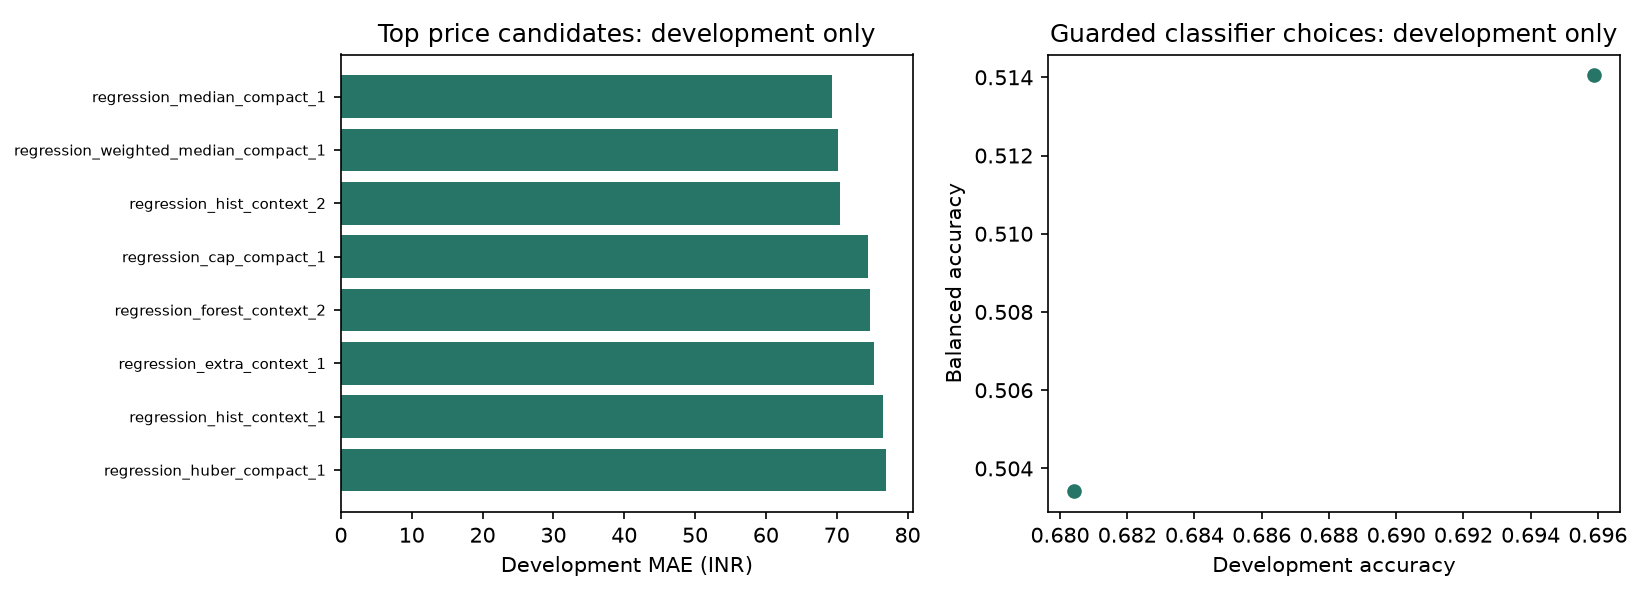

,Frozen choices
regression,"{'spec': {'id': 'regression_median_compact_1',..."
classification,{'spec': {'id': 'classification_forest_context...


In [4]:
display(pd.read_csv(out/'regression_search.csv').head(10))
display(pd.read_csv(out/'classification_search.csv').head(10))
display(pd.read_csv(out/'guarded_classification_search.csv').head(10))
display(Image(filename=str(root/'figures/refinement/development_comparisons.png')))
selected=json.loads((root/'config/refined_selection.json').read_text())
display(pd.Series(selected['selection'],name='Frozen choices').to_frame())

## 4. Same-new-data comparison

The following call verifies and reuses the recorded external evaluation. It does not refit, tune or rescore models. Both the unchanged 149-row original and a 253-row refit are compared on exactly the same 17 new IPOs, separating the effect of more data from tuning.

Reusing recorded refinement evaluation.


,method,task,threshold,mae_inr,rmse_inr,mape_pct,n,accuracy,balanced_accuracy,precision_apply,recall_apply,f1_apply,specificity_skip,brier,tn,fp,fn,tp,predicted_apply,predicted_skip
0,refined_v2,regression,0.50,50.9484,69.6955,19.7136,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,original_v1_149_train,regression,0.50,68.9721,93.6792,25.3343,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,original_architecture_253_train,regression,0.50,50.9484,69.6955,19.7136,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,refined_v2,classification,0.45,NaN,NaN,NaN,17,0.2941,0.5,0.2941,1.0,0.4545,0.0,0.2730,0.0,12.0,0.0,5.0,17.0,0.0
4,original_v1_149_train,classification,0.50,NaN,NaN,NaN,17,0.2941,0.5,0.2941,1.0,0.4545,0.0,0.4315,0.0,12.0,0.0,5.0,17.0,0.0
5,original_architecture_253_train,classification,0.50,NaN,NaN,NaN,17,0.2941,0.5,0.2941,1.0,0.4545,0.0,0.3561,0.0,12.0,0.0,5.0,17.0,0.0
6,announced_cap_baseline,regression,0.50,30.6706,53.4085,11.5186,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,always_apply_baseline,classification,0.50,NaN,NaN,NaN,17,0.2941,0.5,0.2941,1.0,0.4545,0.0,0.7059,0.0,12.0,0.0,5.0,17.0,0.0


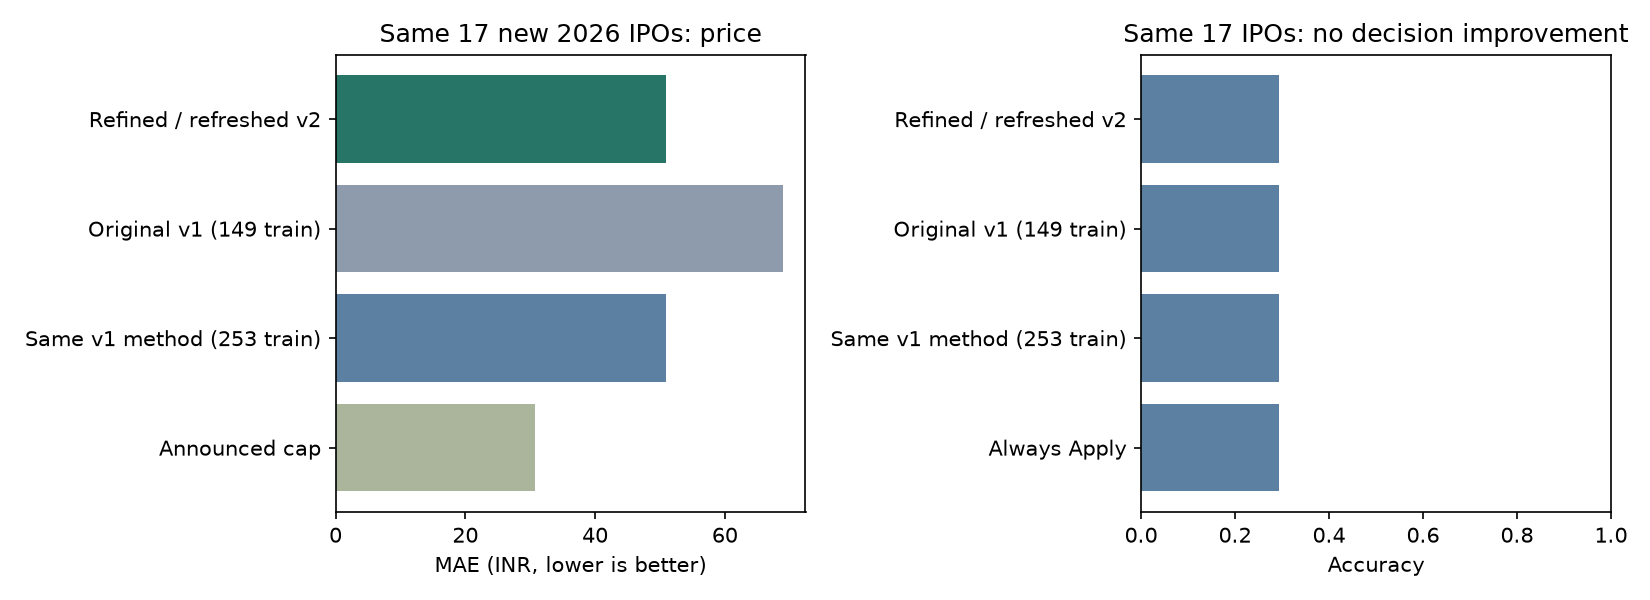

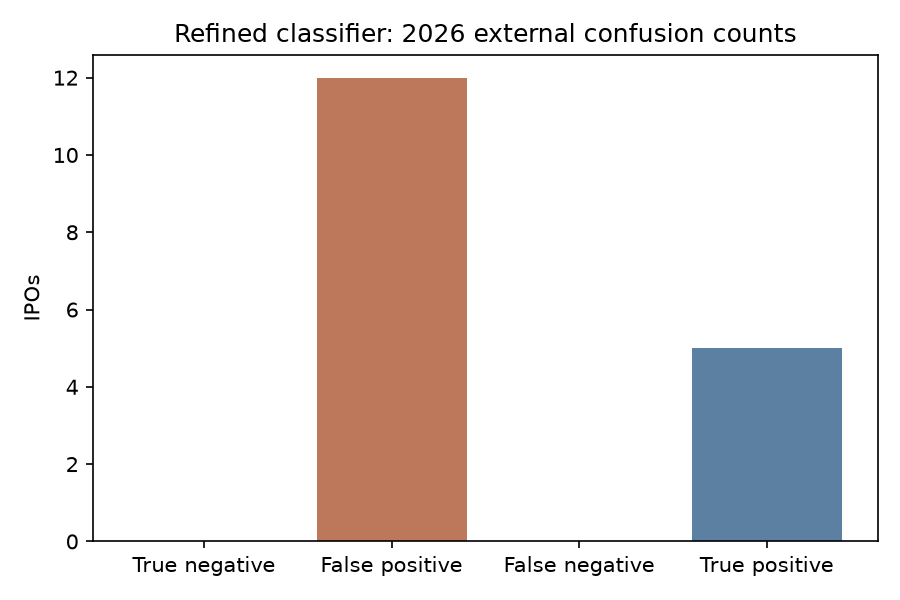

,ipo_id,company_name,symbol,s0_cutoff_at,listing_date,band_low_inr,band_high_inr,predicted_open_inr,positive_gain_probability,predicted_class,signal
0,bharat-coking-coal-7060de,Bharat Coking Coal Limited,BHARATCOAL,2026-01-09 09:00:00+05:30,2026-01-19,21.0,23.0,25.457265,0.491190,1,Apply
1,amagi-media-labs-88941f,Amagi Media Labs Limited,AMAGI,2026-01-13 09:00:00+05:30,2026-01-21,343.0,361.0,399.568376,0.504520,1,Apply
2,shadowfax-technologies-79b8d7,Shadowfax Technologies Limited,SHADOWFAX,2026-01-20 09:00:00+05:30,2026-01-28,118.0,124.0,137.247863,0.534182,1,Apply
3,aye-finance-603dea,Aye Finance Limited,AYE,2026-02-09 09:00:00+05:30,2026-02-16,122.0,129.0,142.782051,0.543346,1,Apply
4,fractal-analytics-cd2759,Fractal Analytics Limited,FRACTAL,2026-02-09 09:00:00+05:30,2026-02-16,857.0,900.0,996.153846,0.538123,1,Apply
5,gaudium-ivf-women-health-5519bb,Gaudium IVF and Women Health Limited,GAUDIUMIVF,2026-02-20 09:00:00+05:30,2026-02-27,75.0,79.0,87.440171,0.615496,1,Apply
6,clean-max-enviro-energy-solutions-822e5c,Clean Max Enviro Energy Solutions Limited,CLEANMAX,2026-02-23 09:00:00+05:30,2026-03-02,1000.0,1053.0,1165.500000,0.593300,1,Apply
7,shree-ram-twistex-6be8bc,Shree Ram Twistex Limited,SRTL,2026-02-23 09:00:00+05:30,2026-03-02,95.0,104.0,115.111111,0.568537,1,Apply
8,pngs-reva-diamond-jewellery-021096,PNGS Reva Diamond Jewellery Limited,PNGSREVA,2026-02-24 09:00:00+05:30,2026-03-04,367.0,386.0,427.239316,0.531785,1,Apply
9,omnitech-engineering-a26936,Omnitech Engineering Limited,OMNI,2026-02-25 09:00:00+05:30,2026-03-05,216.0,227.0,251.252137,0.518103,1,Apply


In [5]:
summary=evaluate()
display(pd.read_csv(out/'external_comparison.csv').round(4))
display(Image(filename=str(root/'figures/refinement/before_after_same_new_data.png')))
display(Image(filename=str(root/'figures/refinement/external_confusion_counts.png')))
display(pd.read_parquet(out/'refined_2026_predictions.parquet'))

## 5. Audit conclusion and handoff

No model was retuned after seeing new-test results. Price MAE improves with more training history but still loses to announced cap. The classifier again fails to identify non-positive listings. Preserve the limitation rather than redefining the target or repeatedly changing the split.

In [6]:
display(Markdown((root/'docs/final_model_audit.md').read_text()))
print('Original artifacts preserved:',summary['original_artifacts_preserved'])
print('No external retuning:',summary['no_external_retuning'])
assert summary['external_rows']==17

# Final machine-learning audit and refinement

## Audit outcome

The original pipeline's time ordering, label maturity and training-only preprocessing remain valid under its documented source assumptions. Two modeling weaknesses were identified: absolute price targets mix scale with listing premium, and accuracy-based classifier selection favors always Apply. No leakage-prone final subscription, final issue price, post-listing value or globally fitted transformation was added.

The second pass compared **48 candidates** (21 price / 27 classification) over **eight expanding 2024–2025 folds**, for **384 fits** and **194 out-of-fold validation IPOs**. Search families include Ridge, Huber, Random Forest, Extra Trees and histogram gradient boosting. Price models learn opening-price/announced-cap premium and use cap-proportional training weights. A cap-weighted median baseline is also checked. Both 8- and 12-variable shared input sets avoid unavailable external VIX, unverified manager and financial predictors.

## Development versus test

All **253 original 2023–2025 IPOs are now development data**. The already inspected 2025 period is not represented as a fresh test. Quarterly models use only earlier S0 dates and strictly mature labels. Thresholds and model settings are selected from development out-of-fold results only.

Initial unconstrained balanced-accuracy selection cut accuracy too severely. Before any external scoring, validation-only guardrails were added: accuracy no worse than majority accuracy minus five percentage points, positive-class recall at least 75%, and non-positive specificity at least 10%. That adjustment and the initial choice are preserved in `unconstrained_selection.json`; it was not made after examining new-test scores. Guarded selected forest: depth 3, minimum leaf 5, 200 trees, balanced subsample weighting, context predictors and threshold 0.45.

The actual new chronological test contains **17 previously unused early-2026 IPOs**. It uses small existing source snapshots, not fabricated or randomized samples. Of 94 verified mainboard 2026 records, 48 lack a matching profile, 28 are after the available market history and one lacks an explicit original band. Nifty history ends 30 March 2026. Included previous-session observations are at most seven days old. Past observable listing outcomes update history inputs strictly before each S0. Exact pre-bid publication times remain an assumption, and source verification is inherited from the existing snapshots.

## Same-new-data comparison

| Method | Price MAE (INR) | Classifier accuracy | Balanced accuracy |
|---|---:|---:|---:|
| Original v1, trained on 149 IPOs | 68.97 | 29.41% | 50.00% |
| Same v1 architectures, refitted on 253 | 50.95 | 29.41% | 50.00% |
| Refined v2, trained on 253 | 50.95 | 29.41% | 50.00% |
| Announced-cap / always-Apply baselines | 30.67 | 29.41% | 50.00% |

The price improvement versus the original fit is **26.1%**, but it is explained by more training history; tuning did not find a better price method than the refitted median-premium baseline. Announced cap alone still wins MAE. Do not compare these 17-row errors directly with the older 103-row 2025 errors as though the test population were unchanged.

The refined classifier still predicts Apply for all 17 new IPOs: five true positives, twelve false positives, no true negatives and no false negatives. Its Brier score improves from 0.4315 to 0.2730, but probabilities remain uncalibrated and decision accuracy does not improve. **Useful Skip detection and 90% accuracy remain unproven.** A small source-covered early-2026 sample cannot establish full-year generalization. No further tuning was performed after these test results.

The original v1 classifier relies on VIX/manager features unavailable for this new sample; its fitted imputer handles them as missing. The v2 model avoids those unsupported inputs. This comparability limitation is explicit rather than silently using stale or future data. The always-Apply and announced-cap baselines provide common fully observed comparisons.

## Delivery and runtime behavior

Original models, 2025 predictions, frozen choices and evaluation receipt are unchanged. The 17 new 2026 audit predictions are available in the app under a separate **2026 audit prediction** badge. Historical v1 evaluation and validation examples retain their original outputs. The new branch uses its recorded 0.45 threshold rather than the old hardcoded 0.5. There is no live web retrieval or claim of reliable investment advice.

The tuned model artifacts are in `models/refined/`, their freeze record is `config/refined_selection.json`, full validation and external comparisons are in `outputs/refinement/`, and all 2026 eligibility/provenance tables are in `data/refinement/`. `04_model_audit_and_refinement.ipynb` contains executed explanations, code, tables and charts. A receipt prevents silent changes to the recorded new-data evaluation.

This is a completed, reproducible modeling audit—not a claim that model complexity solved a weak-signal problem. The proper next research step would require stronger point-in-time information and another untouched evaluation period, rather than more attempts to maximize a score on these known outcomes.


Original artifacts preserved: True
No external retuning: True
